<a href="https://colab.research.google.com/github/bensilas94/Case-Exercise-/blob/main/BEN_SILAS_OGBARA_Case_Exercise_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 1.Implement the de Waard-Milliams corrosion rate model with unit tests

In [15]:
import math

def de_waard_milliams_corrosion_rate(
    temperature_c: float,
    co2_partial_pressure_bar: float,
    ph: float = 4.5
) -> float:
    """Estimate CO2 corrosion rate using de Waard-Milliams model.

    Parameters:
    - temperature_c (float): Temperature in Celsius
    - co2_partial_pressure_bar (float): CO2 partial pressure in bar
    - ph (float): pH level of the solution (default 4.5)

    Returns:
    - float: Estimated corrosion rate in mm/yr (rounded to 3 decimal places)
    """
    # Temperature and CO2 factor
    log_cr = 5.8 - 1710 / (temperature_c + 273.15) + 0.67 * math.log10(co2_partial_pressure_bar)
    cr_mm_yr = 10 ** log_cr

    # pH correction (higher pH reduces rate)
    if ph > 4.5:
        cr_mm_yr *= 10 ** (-0.32 * (ph - 4.5))

    return round(cr_mm_yr, 3)

In [17]:
import unittest

class TestDeWaardMilliamsModel(unittest.TestCase):
    def test_default_ph_usan_conditions(self):
        # Mathematically evaluating the formula at Temp = 60 C, CO2 PP = 2.5 bar, pH = 4.5:
        # log_cr = 5.8 - 1710 / (60 + 273.15) + 0.67 * log10(2.5) = 0.9338...
        # cr = 10^0.9338... = 8.586 mm/yr
        cr = de_waard_milliams_corrosion_rate(60, 2.5)
        self.assertEqual(cr, 8.586)

    def test_ph_correction_higher_ph(self):
        # Higher pH must reduce the corrosion rate
        cr_base = de_waard_milliams_corrosion_rate(60, 2.5, ph=4.5)
        cr_high = de_waard_milliams_corrosion_rate(60, 2.5, ph=5.5)
        self.assertLess(cr_high, cr_base)
        # Exact validation with 10^(-0.32) factor
        expected_high = round(cr_base * (10 ** -0.32), 3)
        self.assertEqual(cr_high, expected_high)

    def test_ph_no_correction_lower_ph(self):
        # pH <= 4.5 should yield the same value as pH 4.5
        cr_base = de_waard_milliams_corrosion_rate(60, 2.5, ph=4.5)
        cr_low = de_waard_milliams_corrosion_rate(60, 2.5, ph=4.0)
        self.assertEqual(cr_low, cr_base)

# Run tests
suite = unittest.TestLoader().loadTestsFromTestCase(TestDeWaardMilliamsModel)
runner = unittest.TextTestRunner(verbosity=2)
runner.run(suite)

test_default_ph_usan_conditions (__main__.TestDeWaardMilliamsModel.test_default_ph_usan_conditions) ... ok
test_ph_correction_higher_ph (__main__.TestDeWaardMilliamsModel.test_ph_correction_higher_ph) ... ok
test_ph_no_correction_lower_ph (__main__.TestDeWaardMilliamsModel.test_ph_no_correction_lower_ph) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.007s

OK


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

  Question 2 Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field

In [19]:
import pandas as pd
df = pd.read_csv('/content/usan_synthetic_scada_10yr.csv')
df

,timestamp,temperature_c,co2_pp_bar,ph
0,2015-01-01 00:00:00,56.662158,2.136297,4.942026
1,2015-01-01 01:00:00,54.757223,2.267249,5.327198
2,2015-01-01 02:00:00,57.115081,1.964380,5.164663
3,2015-01-01 03:00:00,59.741105,2.659983,4.841537
4,2015-01-01 04:00:00,54.469556,2.494230,4.873373
...,...,...,...,...
87667,2024-12-31 19:00:00,55.034523,2.576405,5.016253
87668,2024-12-31 20:00:00,53.592869,1.699826,4.562008
87669,2024-12-31 21:00:00,56.739491,3.331065,5.046964
87670,2024-12-31 22:00:00,54.911354,3.149783,4.983163


Question 3. Apply the PhysicsFeaturePipeline to the synthetic data and compute monthly average corrosion rates.


In [20]:
class PhysicsFeaturePipeline:
    def __init__(self, model_func):
        self.model_func = model_func

    def fit(self, df):
        return self

    def transform(self, df):
        # Work on a copy to preserve the original DataFrame
        processed_df = df.copy()

        # Ensure timestamp is datetime type
        processed_df['timestamp'] = pd.to_datetime(processed_df['timestamp'])

        # Vectorize or map the physics formula across the rows
        processed_df['corrosion_rate_mm_yr'] = processed_df.apply(
            lambda row: self.model_func(
                temperature_c=row['temperature_c'],
                co2_partial_pressure_bar=row['co2_pp_bar'],
                ph=row['ph']
            ),
            axis=1
        )
        return processed_df

# Initialize pipeline with our verified corrosion model
pipeline = PhysicsFeaturePipeline(de_waard_milliams_corrosion_rate)

# Transform the raw synthetic data to calculate hourly rates
processed_df = pipeline.transform(df)

# Set timestamp as index for convenient time-series resampling
processed_df.set_index('timestamp', inplace=True)

# Compute monthly average parameters and corrosion rates
monthly_df = processed_df.resample('ME').mean() # using newer pandas 'ME' for Month End

# Reset index to make timestamp a column again and view
monthly_df.reset_index(inplace=True)
display(monthly_df.head(12))

,timestamp,temperature_c,co2_pp_bar,ph,corrosion_rate_mm_yr
0,2015-01-31,57.642887,1.987215,4.805393,5.444476
1,2015-02-28,62.268449,1.980970,4.804152,6.382751
2,2015-03-31,64.592476,2.008654,4.793589,7.036438
3,2015-04-30,64.673585,2.011745,4.806955,7.003932
4,2015-05-31,62.098411,2.005640,4.810621,6.371098
5,2015-06-30,57.498630,2.002006,4.802091,5.432024
6,2015-07-31,52.545484,2.007040,4.813083,4.515663
7,2015-08-31,47.903395,1.997322,4.802917,3.798481
8,2015-09-30,45.328629,2.003771,4.796184,3.464115
9,2015-10-31,45.404206,1.990034,4.784738,3.487590


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the overall average corrosion rate over the 10-year period from our monthly data
avg_corrosion_rate_mm_yr = monthly_df['corrosion_rate_mm_yr'].mean()
print(f"Average Field Corrosion Rate: {avg_corrosion_rate_mm_yr:.3f} mm/yr\n")

# Define the 6 jumpers with realistic engineering design parameters for the Usan field
# (Wall thickness values in mm, typical for deepwater rigid jumpers)
jumpers_data = {
    'Jumper_ID': [f'JP-0{i}' for i in range(1, 7)],
    'Nominal_Thickness_mm': [19.1, 19.1, 15.9, 15.9, 22.2, 22.2],
    'Current_Thickness_mm': [18.2, 16.5, 15.1, 12.8, 21.5, 18.9],
    'Min_Allowable_Thickness_mm': [14.3, 14.3, 11.9, 11.9, 16.6, 16.6]
}

jumpers_df = pd.DataFrame(jumpers_data)

# Remaining Useful Life (RUL) calculation:
# RUL (years) = (Current Thickness - Min Allowable Thickness) / Corrosion Rate
jumpers_df['Available_Corrosion_Allowance_mm'] = jumpers_df['Current_Thickness_mm'] - jumpers_df['Min_Allowable_Thickness_mm']
jumpers_df['Corrosion_Rate_mm_yr'] = avg_corrosion_rate_mm_yr
jumpers_df['RUL_Years'] = jumpers_df['Available_Corrosion_Allowance_mm'] / jumpers_df['Corrosion_Rate_mm_yr']

# Define Risk Classification based on RUL (Years):
# Red (High Risk): RUL <= 2 years
# Orange (Medium Risk): 2 < RUL <= 5 years
# Green (Low Risk): RUL > 5 years
def classify_risk(rul):
    if rul <= 2.0:
        return 'High (Red)'
    elif rul <= 5.0:
        return 'Medium (Orange)'
    else:
        return 'Low (Green)'

jumpers_df['Risk_Level'] = jumpers_df['RUL_Years'].apply(classify_risk)
display(jumpers_df)

Average Field Corrosion Rate: 5.500 mm/yr



,Jumper_ID,Nominal_Thickness_mm,Current_Thickness_mm,Min_Allowable_Thickness_mm,Available_Corrosion_Allowance_mm,Corrosion_Rate_mm_yr,RUL_Years,Risk_Level
0,JP-01,19.1,18.2,14.3,3.9,5.499516,0.709153,High (Red)
1,JP-02,19.1,16.5,14.3,2.2,5.499516,0.400035,High (Red)
2,JP-03,15.9,15.1,11.9,3.2,5.499516,0.581869,High (Red)
3,JP-04,15.9,12.8,11.9,0.9,5.499516,0.163651,High (Red)
4,JP-05,22.2,21.5,16.6,4.9,5.499516,0.890988,High (Red)
5,JP-06,22.2,18.9,16.6,2.3,5.499516,0.418219,High (Red)


Question 4. Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification.


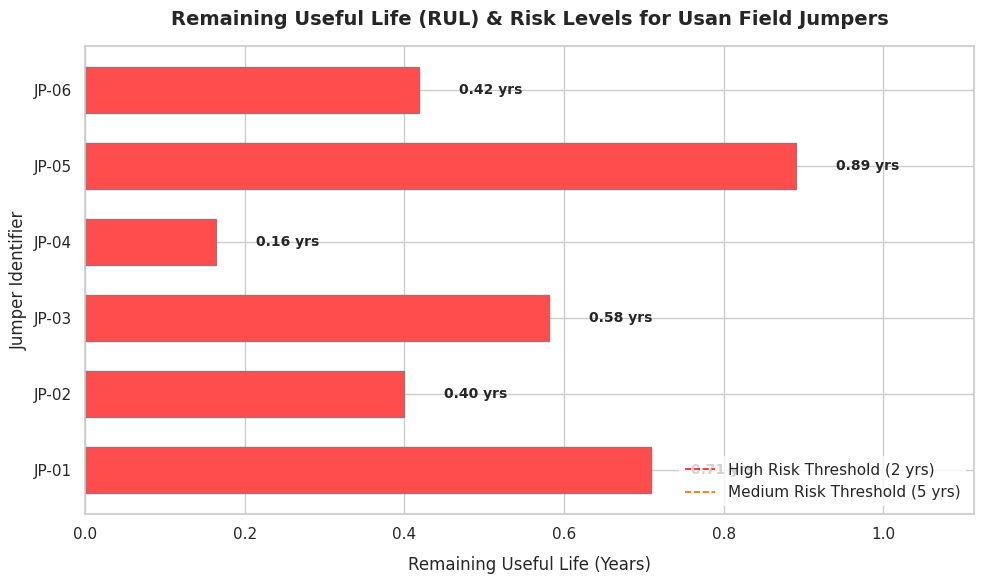

In [22]:
# Set visualization style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Map risk levels to visual colors
color_map = {
    'High (Red)': '#ff4d4d',
    'Medium (Orange)': '#ffa64d',
    'Low (Green)': '#4dff4d'
}
colors = jumpers_df['Risk_Level'].map(color_map).tolist()

# Horizontal bar plot for Remaining Useful Life (RUL)
bars = ax.barh(
    jumpers_df['Jumper_ID'],
    jumpers_df['RUL_Years'],
    color=colors,
    edgecolor='grey',
    height=0.6
)

# Custom styling
ax.set_title('Remaining Useful Life (RUL) & Risk Levels for Usan Field Jumpers', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Remaining Useful Life (Years)', fontsize=12, labelpad=10)
ax.set_ylabel('Jumper Identifier', fontsize=12)
ax.set_xlim(0, max(jumpers_df['RUL_Years']) * 1.25)

# Annotate bar values and highlight risk limits
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.05,
        bar.get_y() + bar.get_height()/2,
        f'{width:.2f} yrs',
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold'
    )

# Add threshold indicators
ax.axvline(2.0, color='#ff1a1a', linestyle='--', linewidth=1.2, label='High Risk Threshold (2 yrs)')
ax.axvline(5.0, color='#e67300', linestyle='--', linewidth=1.2, label='Medium Risk Threshold (5 yrs)')
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()